# Training a Neural Network with Keras: Walkthrough + Guided Practice

**CSCI 345 · Machine Learning** · Based on Chapter 10 of *Hands-On Machine Learning with Scikit-Learn, Keras, and TensorFlow* (A. Géron)

This notebook has two parts:

| Part | What you do |
|---|---|
| **Part 1: Walkthrough** | Follow along as we train a neural network to recognise clothing in **Fashion-MNIST** images. Read each explanation, run each cell, and answer the 💭 *Think* questions in your head (or in a markdown cell). |
| **Part 2: Your turn** | Apply the *same recipe* to a new dataset, **Breast Cancer Wisconsin (Diagnostic)**, by filling in the `TODO` cells. |

### The recipe we'll follow every time

```
1. Load the data          5. Compile (loss, optimizer, metrics)
2. Explore it             6. Train (fit) and watch the learning curves
3. Pre-process it         7. Evaluate on the test set, once
4. Build the model        8. Predict, improve, save
```

> 💡 **Running in Google Colab?** *Runtime → Change runtime type → GPU* makes Part 1 faster, but a CPU is fine too (a few minutes).

---
# Part 1: Walkthrough with Fashion-MNIST

## Step 0: Set up

We use **Keras**, the high-level neural-network library that ships inside TensorFlow.
Setting a random seed makes results (nearly) repeatable, so your numbers will be close to your neighbour's.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import tensorflow as tf
from tensorflow import keras

from sklearn.metrics import ConfusionMatrixDisplay, classification_report

print("TensorFlow version:", tf.__version__)
print("Keras version:     ", keras.__version__)

keras.utils.set_random_seed(42)   # seeds Python, NumPy and TensorFlow in one call

TensorFlow version: 2.21.0
Keras version:      3.15.1


## Step 1: Load the data

**Fashion-MNIST** (from Zalando Research) has 70,000 grayscale images of clothing, each **28 × 28 pixels**, in **10 classes**.
Keras can download it for us, already split into a training set (60,000) and a test set (10,000).

In [2]:
(X_train_full, y_train_full), (X_test, y_test) = keras.datasets.fashion_mnist.load_data()

print("X_train_full:", X_train_full.shape, X_train_full.dtype)
print("y_train_full:", y_train_full.shape, y_train_full.dtype)
print("X_test:      ", X_test.shape)

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 1us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
X_train_full: (60000, 28, 28) uint8
y_train_full: (60000,) uint8
X_test:       (10000, 28, 28)


Each label is a number 0–9. This list turns a number into a name: label `2` means `class_names[2]`, which is `"Pullover"`.

In [3]:
class_names = ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
               "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]

## Step 2: Explore the data

**Always look at your data before modelling it.** Three quick checks:
what do examples look like, are the classes balanced, and what range are the values in?

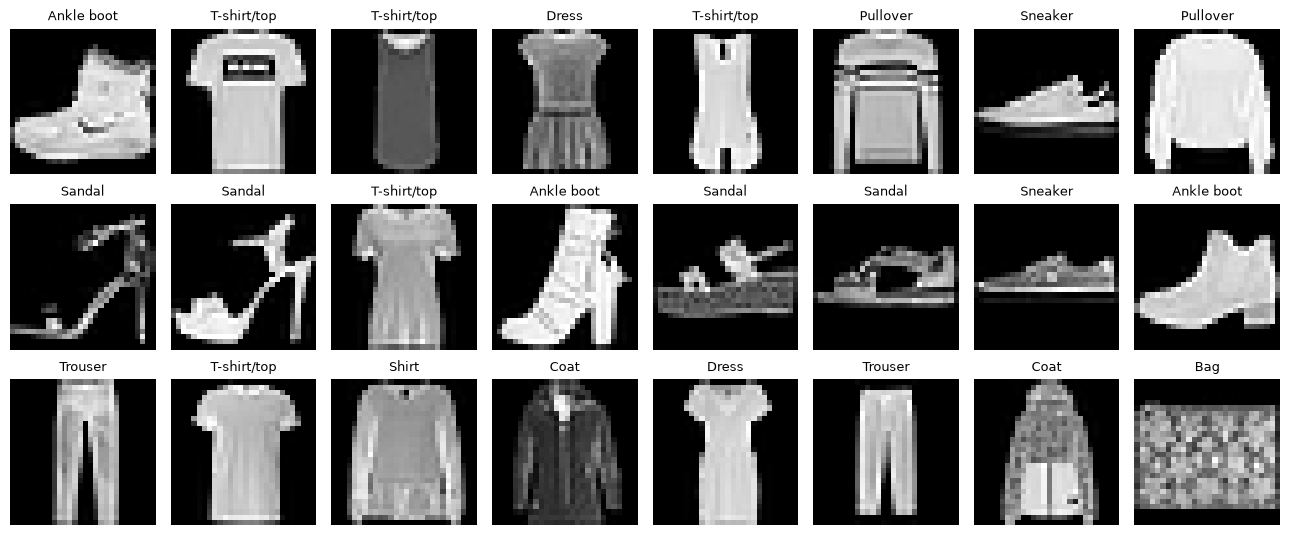

In [4]:
# 1) What do the images look like?
fig, axes = plt.subplots(3, 8, figsize=(13, 5.5))
for ax, i in zip(axes.flat, range(24)):
    ax.imshow(X_train_full[i], cmap="gray")
    ax.set_title(class_names[y_train_full[i]], fontsize=9)
    ax.axis("off")
plt.tight_layout()
plt.show()

In [5]:
# 2) Are the classes balanced?
counts = pd.Series(y_train_full).map(dict(enumerate(class_names))).value_counts()
print(counts)

# 3) What range are the pixel values in?
print("\nPixel values range from", X_train_full.min(), "to", X_train_full.max())

Ankle boot     6000
T-shirt/top    6000
Dress          6000
Pullover       6000
Sneaker        6000
Sandal         6000
Trouser        6000
Shirt          6000
Coat           6000
Bag            6000
Name: count, dtype: int64

Pixel values range from 0 to 255


💭 **Think:** Every class has exactly 6,000 training images. Why is that good news when we judge the model by *accuracy*?

> *If one class were 90% of the data, a "model" that always guessed that class would score 90% accuracy while learning nothing.
> With balanced classes, random guessing gets only 10%.*

## Step 3: Pre-process the data

Two jobs:

1. **Scale** the pixels from 0–255 down to 0–1. Neural networks train much better when inputs are small and on a similar scale,
   because gradient descent takes sensible-size steps.
2. **Split** off a **validation set**. We now have three sets, each with one job:

| Set | Size | Used for |
|---|---|---|
| **Training** | 55,000 | Learning the weights |
| **Validation** | 5,000 | Checking progress *during* training and choosing settings (epochs, layer sizes …) |
| **Test** | 10,000 | One final, honest score **at the very end**. Never used for decisions. |

> ⚠️ If you tune your model by looking at the **test** score, the test set stops being "unseen data" and your final score becomes too optimistic.

In [6]:
X_valid, X_train = X_train_full[:5000] / 255.0, X_train_full[5000:] / 255.0
y_valid, y_train = y_train_full[:5000], y_train_full[5000:]
X_test = X_test / 255.0

print("train:", X_train.shape, " valid:", X_valid.shape, " test:", X_test.shape)
print("pixel range now:", X_train.min(), "to", X_train.max())

train: (55000, 28, 28)  valid: (5000, 28, 28)  test: (10000, 28, 28)
pixel range now: 0.0 to 1.0


## Step 4: Build the model

We build a **multilayer perceptron (MLP)**, exactly the kind of network from our MLP lecture, with the **Sequential API**
(a simple stack of layers, one after another):

| Layer | What it does |
|---|---|
| `Input(shape=(28, 28))` | Declares the shape of one example |
| `Flatten` | Unrolls the 28 × 28 grid into a vector of **784** numbers (no learning here) |
| `Dense(300, relu)` | Hidden layer 1: 300 neurons, each a weighted sum + ReLU |
| `Dense(100, relu)` | Hidden layer 2: 100 neurons |
| `Dense(10, softmax)` | Output layer: **one neuron per class**. Softmax turns the 10 scores into probabilities that add up to 1 |

In [7]:
model = keras.Sequential([
    keras.Input(shape=(28, 28)),
    keras.layers.Flatten(name="flatten"),
    keras.layers.Dense(300, activation="relu", name="hidden_1"),
    keras.layers.Dense(100, activation="relu", name="hidden_2"),
    keras.layers.Dense(10, activation="softmax", name="output"),
])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ hidden_1 (Dense)                │ (None, 300)            │       235,500 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ hidden_2 (Dense)                │ (None, 100)            │        30,100 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 10)             │         1,010 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 266,610 (1.02 MB)

 Trainable params: 266,610 (1.02 MB)

 Non-trainable params: 0 (0.00 B)

### Where do the parameter counts come from?

A `Dense` layer has **(inputs × neurons) weights + (neurons) biases**:

| Layer | Calculation | Parameters |
|---|---|---|
| hidden_1 | 784 × 300 + 300 | 235,500 |
| hidden_2 | 300 × 100 + 100 | 30,100 |
| output | 100 × 10 + 10 | 1,010 |
| **Total** | | **266,610** |

That's 266,610 numbers that training must tune, and they all start out **random**.

### Sanity check before training

An untrained network should be no better than random guessing. Let's predict one image:

In [8]:
probs = model.predict(X_valid[:1], verbose=0)[0]
print("Predicted probabilities:", np.round(probs, 3))
print("They sum to:", probs.sum().round(3))
print("Predicted:", class_names[probs.argmax()], "| Actual:", class_names[y_valid[0]])

Predicted probabilities: [0.196 0.112 0.077 0.099 0.119 0.097 0.064 0.106 0.074 0.057]
They sum to: 1.0
Predicted: T-shirt/top | Actual: Ankle boot


💭 **Think:** The 10 probabilities are all roughly 0.1. Why does that make sense *before* training?

That does make sense. This is just random guessing and there are ten options so all of the odds are 1/10.

## Step 5: Compile the model

`compile()` tells Keras **how** to learn:

| Setting | Our choice | Meaning |
|---|---|---|
| `loss` | `"sparse_categorical_crossentropy"` | How wrong a prediction is. *Sparse* because our labels are integers 0–9 (with one-hot labels you'd use `"categorical_crossentropy"`). |
| `optimizer` | SGD, learning rate 0.01 | The algorithm that updates the weights: **gradient descent** using **backpropagation** |
| `metrics` | `["accuracy"]` | Extra numbers to *report*. The optimizer minimises the **loss**, not the metrics. |

**Quick rule for the output layer and loss:**

| Task | Output layer | Loss |
|---|---|---|
| Multi-class (one of *k*) | `Dense(k, "softmax")` | `sparse_categorical_crossentropy` |
| Binary (yes / no) | `Dense(1, "sigmoid")` | `binary_crossentropy` |
| Regression (a number) | `Dense(1)` (no activation) | `mse` |

*(You will use the binary row in Part 2.)*

In [10]:
model.compile(loss="sparse_categorical_crossentropy",
              optimizer=keras.optimizers.SGD(learning_rate=0.01),
              metrics=["accuracy"])

# Loss before any training: with 10 classes, random guessing gives about -ln(1/10) = 2.30
loss0, acc0 = model.evaluate(X_valid, y_valid, verbose=1)
print(f"Before training: loss = {loss0:.2f} (expect about 2.30), accuracy = {acc0:.1%} (expect about 10%)")

157/157 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.0552 - loss: 2.3729
Before training: loss = 2.37 (expect about 2.30), accuracy = 5.5% (expect about 10%)


## Step 6: Train the model

`fit()` runs the training loop. Key terms:

- **Batch:** Keras feeds 32 images at a time (the default). After each batch it does one forward pass, computes the loss,
  backpropagates and updates the weights. This is *mini-batch* gradient descent.
- **Epoch:** one full pass over all 55,000 training images, i.e. 55,000 / 32 ≈ **1,719 batches**.
- **`validation_data`:** after each epoch, Keras reports the loss and accuracy on the validation set. The weights are **not** trained on it.

We save what `fit()` returns in `history`, a record of every epoch.

In [11]:
history = model.fit(X_train, y_train,
                    epochs=30,
                    validation_data=(X_valid, y_valid))

Epoch 1/30
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.7621 - loss: 0.7272 - val_accuracy: 0.8258 - val_loss: 0.5121
Epoch 2/30
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.8294 - loss: 0.4896 - val_accuracy: 0.8496 - val_loss: 0.4467
Epoch 3/30
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.8445 - loss: 0.4429 - val_accuracy: 0.8578 - val_loss: 0.4159
Epoch 4/30
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.8535 - loss: 0.4144 - val_accuracy: 0.8622 - val_loss: 0.3951
Epoch 5/30
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.8607 - loss: 0.3939 - val_accuracy: 0.8664 - val_loss: 0.3804
Epoch 6/30
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.8654 - loss: 0.3779 - val_accuracy: 0.8694 - val_loss: 0.3687
Epoch 7/30
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.8704 - loss: 0.3644 - val_accuracy: 0.8716 - val_loss: 0.3599
Epoch 8/30
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.8743 - loss: 0.3528 - 

### Read the learning curves

These plots are the most useful diagnostic you have.

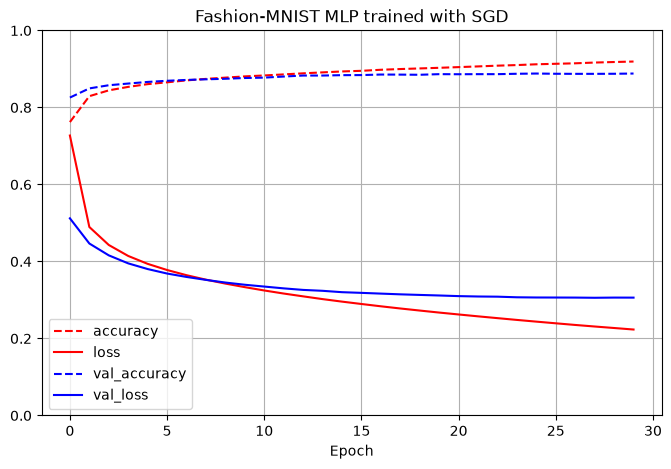

In [12]:
def plot_history(history, title=""):
    pd.DataFrame(history.history).plot(figsize=(8, 5), grid=True,
                                       xlabel="Epoch", style=["r--", "r-", "b--", "b-"])
    plt.gca().set_ylim(0, 1)
    plt.title(title)
    plt.show()

plot_history(history, "Fashion-MNIST MLP trained with SGD")

**How to read them:**

| You see | It means | Try |
|---|---|---|
| Training and validation curves stay close and are still improving | Under-trained | More epochs |
| Training keeps improving, **validation flattens or gets worse** | **Overfitting**: memorising the training set | Stop earlier, use more data, regularise (e.g. dropout) |
| Both curves are bad | Model too simple, or learning rate wrong | Bigger model, tune the learning rate |

💭 **Think:** Around which epoch does validation loss stop improving? Is there a gap between training and validation accuracy at the end?

Validation loss stops improving at epoch 20. Past epoch 15 there starts to be a gap between the training and validation accuracy.

## Step 7: Evaluate on the test set (once!)

We have finished making decisions, so now we get the honest score on data the model has never seen.

In [13]:
test_loss, test_acc = model.evaluate(X_test, y_test, verbose=0)
print(f"Test accuracy: {test_acc:.2%}   (test loss {test_loss:.3f})")

Test accuracy: 87.82%   (test loss 0.345)


You should see roughly **88%**. Accuracy is a single number, though. **Which** classes does the model confuse?
A **confusion matrix** shows this: rows are true classes, columns are predicted classes, and the diagonal counts the correct predictions.

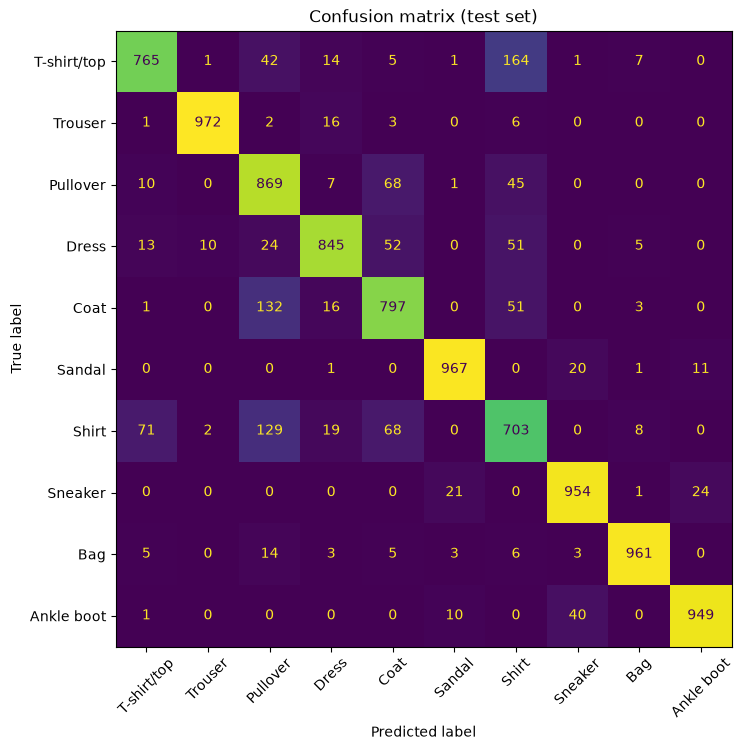

              precision    recall  f1-score   support

 T-shirt/top      0.882     0.765     0.819      1000
     Trouser      0.987     0.972     0.979      1000
    Pullover      0.717     0.869     0.786      1000
       Dress      0.917     0.845     0.880      1000
        Coat      0.799     0.797     0.798      1000
      Sandal      0.964     0.967     0.966      1000
       Shirt      0.685     0.703     0.694      1000
     Sneaker      0.937     0.954     0.945      1000
         Bag      0.975     0.961     0.968      1000
  Ankle boot      0.964     0.949     0.957      1000

    accuracy                          0.878     10000
   macro avg      0.883     0.878     0.879     10000
weighted avg      0.883     0.878     0.879     10000



In [14]:
y_proba = model.predict(X_test, verbose=0)    # shape (10000, 10): a probability per class
y_pred = y_proba.argmax(axis=1)               # pick the most likely class

fig, ax = plt.subplots(figsize=(9, 8))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=class_names,
                                        xticks_rotation=45, ax=ax, colorbar=False)
plt.title("Confusion matrix (test set)")
plt.show()

print(classification_report(y_test, y_pred, target_names=class_names, digits=3))

💭 **Think:** Which class has the lowest recall? Which classes is it most often confused with? Does that match what *you* saw in Step 2?

> *Usually **Shirt**: it gets mistaken for T-shirt/top, Pullover and Coat. Even humans struggle with these at 28 × 28.*

The T-shirt/top and Shirt get confused together frequently. That does match with what I saw.

## Step 8: Predict, improve, save

### 8a. Look at individual predictions

The title shows *predicted (confidence)* and the true label. Green means correct, red means wrong.

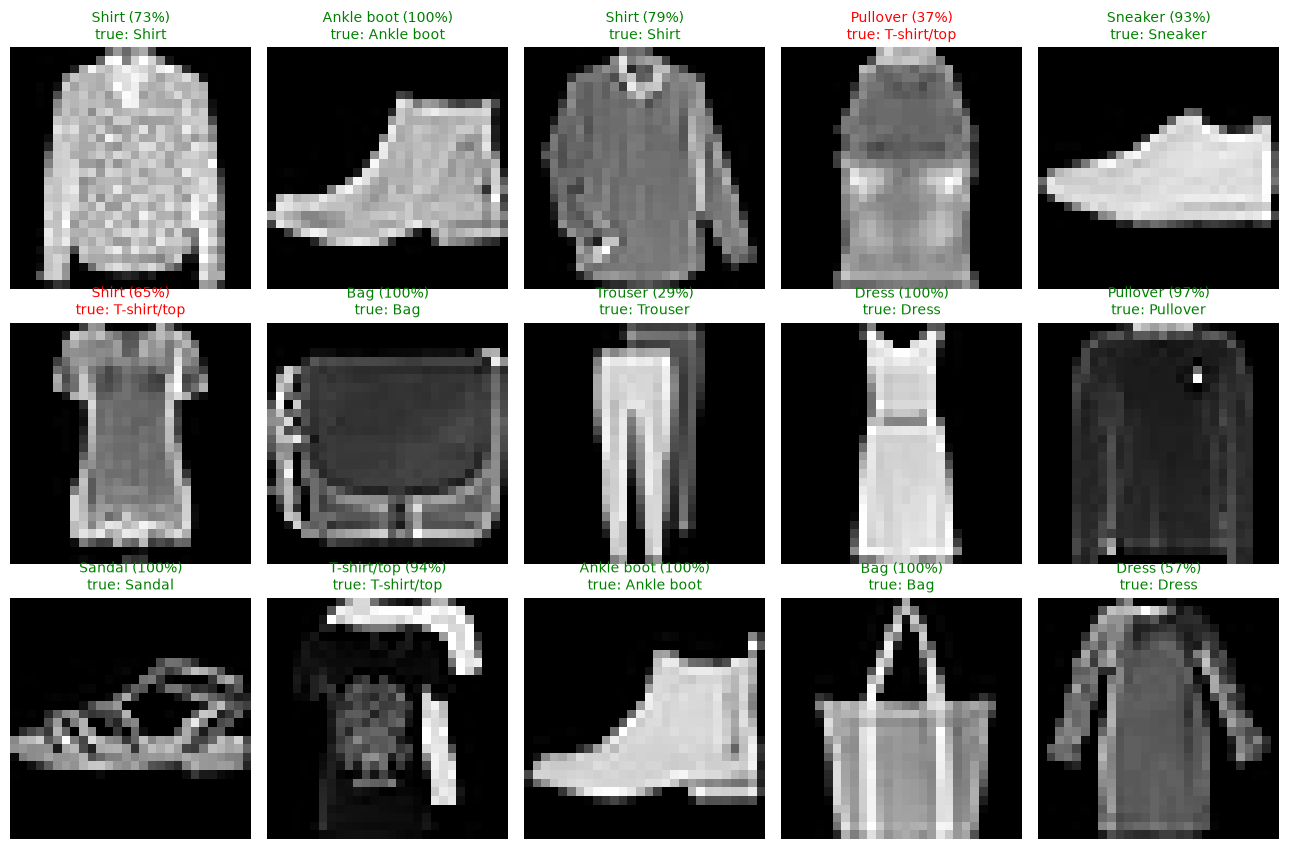

In [15]:
def show_predictions(model, X, y, n=15, seed=0):
    rng = np.random.default_rng(seed)
    idx = rng.choice(len(X), size=n, replace=False)
    probs = model.predict(X[idx], verbose=0)
    fig, axes = plt.subplots(3, 5, figsize=(13, 8.5))
    for ax, i, p in zip(axes.flat, idx, probs):
        pred = p.argmax()
        ax.imshow(X[i], cmap="gray")
        ax.set_title(f"{class_names[pred]} ({p[pred]:.0%})\ntrue: {class_names[y[i]]}",
                     color="green" if pred == y[i] else "red", fontsize=10)
        ax.axis("off")
    plt.tight_layout()
    plt.show()

show_predictions(model, X_test, y_test)

### 8b. Improve: a better optimizer and early stopping

Two common upgrades:

- **Adam** optimizer: adapts the learning rate for every weight, so it usually trains faster than plain SGD.
- **Callbacks**: functions Keras calls during training.
  - `EarlyStopping` watches `val_loss` and **stops** when it hasn't improved for `patience` epochs.
    `restore_best_weights=True` then rolls back to the best epoch. So we can ask for many epochs without worrying about overfitting.
  - `ModelCheckpoint` saves the best model to disk while training.

We'll also build the model with the **Functional API** inside a function, which makes it easy to try different sizes.
In the functional style each layer is *called* on the output of the previous one:

Epoch 1/100
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.8012 - loss: 0.5495 - val_accuracy: 0.8572 - val_loss: 0.3900
Epoch 2/100
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.8487 - loss: 0.4122 - val_accuracy: 0.8654 - val_loss: 0.3577
Epoch 3/100
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.8629 - loss: 0.3738 - val_accuracy: 0.8816 - val_loss: 0.3313
Epoch 4/100
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.8705 - loss: 0.3543 - val_accuracy: 0.8818 - val_loss: 0.3289
Epoch 5/100
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.8757 - loss: 0.3374 - val_accuracy: 0.8834 - val_loss: 0.3209
Epoch 6/100
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.8803 - loss: 0.3238 - val_accuracy: 0.8856 - val_loss: 0.3203
Epoch 7/100
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.8850 - loss: 0.3142 - val_accuracy: 0.8864 - val_loss: 0.3129
Epoch 8/100
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.8867 - loss: 0

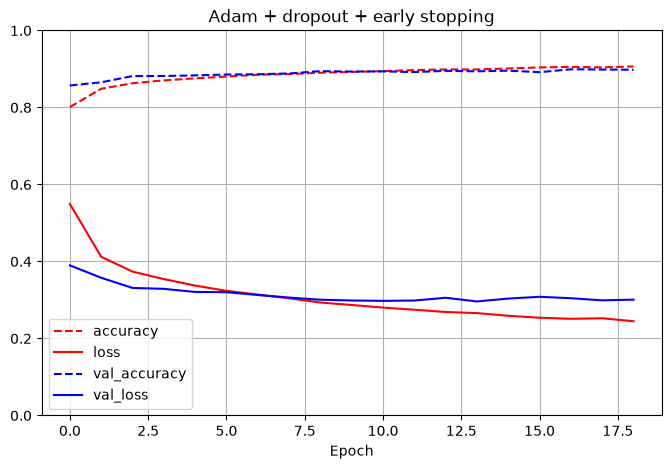

In [16]:
def build_model(hidden=(300, 100), dropout=0.0):
    inputs = keras.Input(shape=(28, 28))
    x = keras.layers.Flatten()(inputs)
    for units in hidden:
        x = keras.layers.Dense(units, activation="relu")(x)
        if dropout > 0:
            x = keras.layers.Dropout(dropout)(x)   # randomly switches off neurons while training
    outputs = keras.layers.Dense(10, activation="softmax")(x)
    return keras.Model(inputs, outputs)

keras.utils.set_random_seed(42)
model2 = build_model(hidden=(300, 100), dropout=0.2)
model2.compile(loss="sparse_categorical_crossentropy",
               optimizer=keras.optimizers.Adam(learning_rate=1e-3),
               metrics=["accuracy"])

callbacks = [
    keras.callbacks.EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True, verbose=1),
    keras.callbacks.ModelCheckpoint("best_fashion_mlp.keras", monitor="val_loss", save_best_only=True),
]

history2 = model2.fit(X_train, y_train, epochs=100,
                      validation_data=(X_valid, y_valid),     # validation, never test!
                      callbacks=callbacks)

plot_history(history2, "Adam + dropout + early stopping")

In [17]:
for name, m in [("SGD, 30 epochs", model), ("Adam + dropout + early stopping", model2)]:
    loss, acc = m.evaluate(X_test, y_test, verbose=0)
    print(f"{name:35s} test accuracy = {acc:.2%}")

SGD, 30 epochs                      test accuracy = 87.82%
Adam + dropout + early stopping     test accuracy = 87.95%


💭 **Think:** How many epochs did early stopping actually run? Compare the gap between the training and validation curves with the first model's.

> **Optional: TensorBoard (Colab).** Add `keras.callbacks.TensorBoard("logs")` to the callbacks list, then run `%load_ext tensorboard`
> and `%tensorboard --logdir logs` to explore the curves interactively.

Early stopping only ran through 19 epochs because it stopped improving after epoch 14. The trainig curves start out much sharper but flatten quicker.

### 8c. Save and reload

A trained model is just a file. Save it, load it back later (or in another program), and predict, with no retraining needed.

In [18]:
model2.save("fashion_mlp.keras")
reloaded = keras.models.load_model("fashion_mlp.keras")

same = np.allclose(model2.predict(X_test[:5], verbose=0), reloaded.predict(X_test[:5], verbose=0))
print("Reloaded model gives identical predictions:", same)

Reloaded model gives identical predictions: True


## Part 1 recap: the Keras cheat sheet

```python
model = keras.Sequential([keras.Input(shape=...),                 # 4. build
                          keras.layers.Dense(n, activation="relu"),
                          keras.layers.Dense(k, activation="softmax")])
model.compile(loss="...", optimizer="adam", metrics=["accuracy"])  # 5. compile
history = model.fit(X_train, y_train, epochs=..., validation_data=(X_valid, y_valid),
                    callbacks=[keras.callbacks.EarlyStopping(patience=5, restore_best_weights=True)])  # 6. train
model.evaluate(X_test, y_test)                                     # 7. evaluate (once)
model.predict(X_new)                                               # 8. predict
model.save("my_model.keras")                                       #    save
```

**Sequential vs Functional API:** they build the same models here. The Functional API also handles models that are *not* a single
stack: several inputs or outputs, branches, and skip connections. That is why most modern architectures use it.

---
# Part 2: Your turn. Breast cancer diagnosis

### The dataset

**Breast Cancer Wisconsin (Diagnostic)**, from the UCI Machine Learning Repository:
🔗 https://archive.ics.uci.edu/dataset/17/breast-cancer-wisconsin-diagnostic

- **569** patients, each a fine-needle-aspirate image of a breast mass, described by **30 numeric features**
  (radius, texture, perimeter, area, smoothness … each as mean, standard error, and worst value).
- **Target:** is the mass **malignant** (cancerous) or **benign**?
- License: CC BY 4.0. It ships with scikit-learn, so no download is needed:
  [`sklearn.datasets.load_breast_cancer`](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_breast_cancer.html).

### What's different from Part 1?

| | Part 1 (Fashion-MNIST) | Part 2 (Breast cancer) |
|---|---|---|
| Data | Images, 784 pixels | **Tabular**, 30 measurements |
| Task | 10-class | **Binary** (malignant vs benign) |
| Size | 70,000 | **569**, small, so overfitting is a real risk |
| Scaling | Divide by 255 | Features on wildly different scales, so use **`StandardScaler`** |
| Mistakes | All equally bad | **Missing a cancer is much worse** than a false alarm |

### How to work

Fill in every cell marked **`# TODO`**, run it, and check the ✅ **Check** line before moving on.
Hints are in the comments. Answer the ✍️ questions in the markdown cells.

## P1: Load the data

`load_breast_cancer` labels **malignant = 0** and **benign = 1**. We flip that so that **1 = malignant**: the positive class should
be the one we care about *finding*, which makes *recall* mean "fraction of cancers detected".

In [19]:
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

data = load_breast_cancer(as_frame=True)
X_bc = data.data                 # DataFrame: 569 rows x 30 columns
y_bc = 1 - data.target           # now 1 = malignant, 0 = benign
bc_names = ["benign", "malignant"]

X_bc.head()

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


## P2: Explore

✍️ Answer from your output: How many malignant and benign cases are there? Is the dataset balanced?
What is the smallest and largest feature value in the whole table, and why might that hurt a neural network?

In [22]:
print(y_bc.value_counts())
#   hint: y_bc.value_counts()


# TODO 2: look at the feature scales
#   hint: X_bc.describe().T[["mean", "min", "max"]]  and  X_bc.values.min(), X_bc.values.max()
X_bc.describe().T[['mean', 'min', 'max']].sort_values(by = 'max', ascending = True)

target
0    357
1    212
Name: count, dtype: int64


,mean,min,max
fractal dimension error,0.003795,0.000895,0.02984
smoothness error,0.007041,0.001713,0.03113
concave points error,0.011796,0.000000,0.05279
symmetry error,0.020542,0.007882,0.07895
mean fractal dimension,0.062798,0.049960,0.09744
compactness error,0.025478,0.002252,0.13540
mean smoothness,0.096360,0.052630,0.16340
mean concave points,0.048919,0.000000,0.20120
worst fractal dimension,0.083946,0.055040,0.20750
worst smoothness,0.132369,0.071170,0.22260


✅ **Check:** 212 malignant, 357 benign. Values range from 0 up to roughly 4,250.

## P3: Split and scale

1. Split into **train 60% / validation 20% / test 20%**. Use `stratify=` so every set keeps the same malignant/benign ratio.
2. **Scale** with `StandardScaler` (each feature gets mean 0 and std 1).
   **Fit the scaler on the training set only**, then `transform` all three sets.

💭 Why fit only on the training set? If the scaler sees validation or test data, information from those sets leaks into training
(**data leakage**), and your scores become too optimistic.

In [27]:
X_temp, X_test, y_temp, y_test = train_test_split(X_bc,y_bc, test_size=0.2, stratify=y_bc, random_state=42)
X_train, X_valid, y_train, y_valid = train_test_split(X_temp, y_temp, test_size=0.25, stratify=y_temp, random_state= 42)

scaler = StandardScaler()
scaler.fit(X_train)
X_tr_s = scaler.transform(X_train)
X_va_s = scaler.transform(X_valid)
X_te_s = scaler.transform(X_test)

print("train:", X_train.shape, " valid:", X_valid.shape, " test:", X_test.shape)

train: (341, 30)  valid: (114, 30)  test: (114, 30)


✅ **Check:** train (341, 30), valid (114, 30), test (114, 30). Name your scaled arrays `X_tr_s`, `X_va_s`, `X_te_s`.

## P4: Build the model

Build a small MLP. With only 341 training examples, a 266,610-parameter network like Part 1's would overfit badly.

- Input: 30 features
- Hidden: `Dense(16, relu)`, then `Dense(8, relu)`
- Output: **binary task**, so check the table in Step 5: how many neurons, and which activation?

✍️ How many parameters does your model have? Work it out by hand first, then compare with `summary()`.

In [34]:
keras.utils.set_random_seed(42)


bc_model = keras.Sequential([
    keras.Input(shape=(30,)),
    keras.layers.Dense(16, 'relu'),
    keras.layers.Dense(8, 'relu'),
    keras.layers.Dense(1, 'sigmoid')

])
bc_model.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_9 (Dense)                 │ (None, 16)             │           496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 641 (2.50 KB)

 Trainable params: 641 (2.50 KB)

 Non-trainable params: 0 (0.00 B)

✅ **Check:** total parameters = **641**. If you got 650, your output layer has 2 neurons. Re-read the table.

## P5: Compile

Use `binary_crossentropy`, the `adam` optimizer, and track **accuracy** *and* **recall**
(`keras.metrics.Recall(name="recall")`), the fraction of malignant cases the model catches.

In [35]:

bc_model.compile(
    loss= 'binary_crossentropy',
    optimizer= keras.optimizers.Adam(learning_rate = 0.001),
    metrics=['accuracy', 'recall'],
)

## P6: Train with early stopping

Train for up to **200 epochs** with `batch_size=32`, validating on the **validation** set, and stop early when `val_loss` hasn't
improved for **15** epochs (restore the best weights). Then plot the learning curves.

Epoch 1/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 25ms/step - accuracy: 0.5924 - loss: 0.6761 - recall: 0.4252 - val_accuracy: 0.6754 - val_loss: 0.6153 - val_recall: 0.4651
Epoch 2/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.7302 - loss: 0.5690 - recall: 0.4803 - val_accuracy: 0.7895 - val_loss: 0.5253 - val_recall: 0.5349
Epoch 3/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.7918 - loss: 0.4934 - recall: 0.5512 - val_accuracy: 0.8421 - val_loss: 0.4591 - val_recall: 0.6279
Epoch 4/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.8680 - loss: 0.4340 - recall: 0.6929 - val_accuracy: 0.8947 - val_loss: 0.4057 - val_recall: 0.7442
Epoch 5/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.9003 - loss: 0.3829 - recall: 0.7638 - val_accuracy: 0.9386 - val_loss: 0.3593 - val_recall: 0.8372
Epoch 6/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.9179 - loss: 0.3386 - recall: 0.8110 - val_accuracy: 0.9474 - val_loss: 0.3181 - val_recall: 0.8605
Epoch 7/2

<Axes: xlabel='Epoch'>

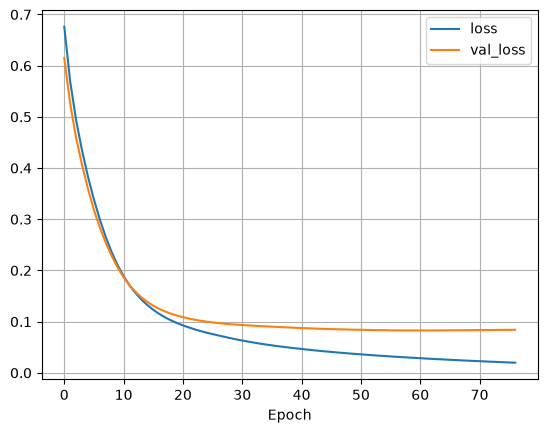

In [36]:

early = keras.callbacks.EarlyStopping(monitor = 'val_loss', patience = 15, restore_best_weights = True, verbose = 1)

bc_history = bc_model.fit(X_tr_s, y_train, epochs=200, batch_size=32, validation_data=(X_va_s, y_valid), callbacks=early)


pd.DataFrame(bc_history.history)[["loss", "val_loss"]].plot(grid=True, xlabel="Epoch")

✍️ After how many epochs did training stop? Does the model overfit, and how can you tell from the curves?

It stopped after 77 epochs. The model began overfitting at epoch 63 as the loss continues to decrease while the validation loss stays flat.

## P7: Evaluate on the test set

1. `evaluate` on the scaled test set.
2. Predict probabilities and turn them into labels with a **0.5 threshold**.
3. Draw the confusion matrix and print the classification report.

✍️ In a cancer screening tool, which error is worse: a **false negative** (cancer predicted as benign) or a **false positive**? How many of each did your model make?

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.9737 - loss: 0.0906 - recall: 0.9524 
[0.09060035645961761, 0.9736841917037964, 0.9523809552192688]


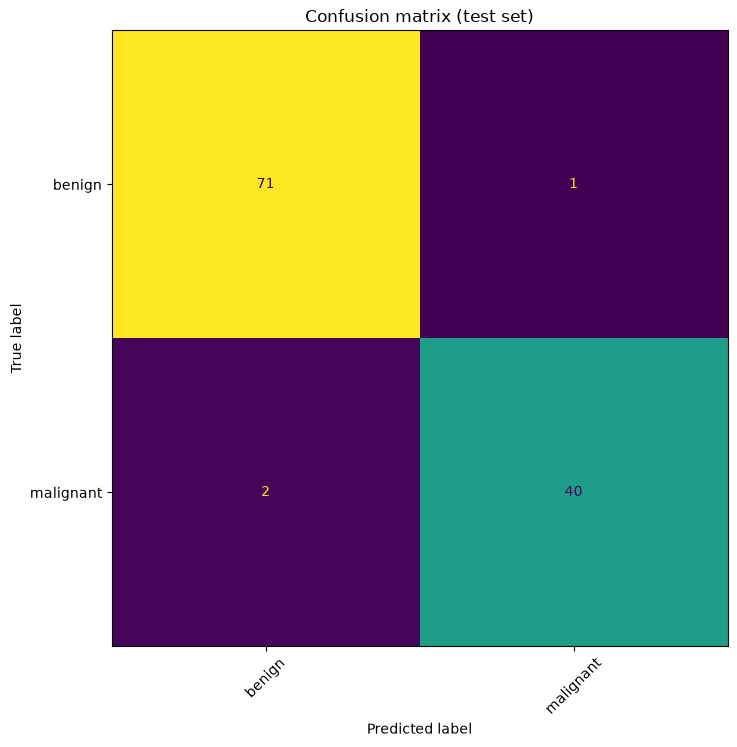

              precision    recall  f1-score   support

      benign      0.973     0.986     0.979        72
   malignant      0.976     0.952     0.964        42

    accuracy                          0.974       114
   macro avg      0.974     0.969     0.972       114
weighted avg      0.974     0.974     0.974       114



In [41]:

results = bc_model.evaluate(X_te_s, y_test)
print(results)


p_te = bc_model.predict(X_te_s, verbose=0).ravel()
y_hat = [1 if x > 0.5 else 0 for x in p_te]

# TODO 11: confusion matrix + classification report (use display_labels=bc_names / target_names=bc_names)
fig, ax = plt.subplots(figsize=(9, 8))

ConfusionMatrixDisplay.from_predictions(y_test, y_hat, display_labels=bc_names,
                                        xticks_rotation=45, ax=ax, colorbar=False)
plt.title("Confusion matrix (test set)")
plt.show()

print(classification_report(y_test, y_hat, target_names=bc_names, digits=3))


✅ **Check:** test accuracy should be about **95% or higher**. If it is around 60%, check that you used the *scaled* arrays.

## P8: Experiment. Change ONE thing

Scientists change one variable at a time. Copy your P4–P7 code into a helper function, then try **each** experiment below, starting
again from the same seed. Record the **test accuracy** and **recall** in the table.

| # | Experiment | Test accuracy | Recall |
|---|---|---|---|
| 0 | Your baseline (P4–P7) |0.9737 |0.9524 |
| 1 | **No scaling**: train on `X_tr`, `X_va`, `X_te` instead of the scaled arrays | | |
| 2 | Much bigger network: `Dense(256)`, then `Dense(128)` | | |
| 3 | Add `Dropout(0.3)` after each hidden layer | | |
| 4 | SGD with `learning_rate=0.001` instead of Adam | | |

✍️ Which change hurt the most? Explain *why*, using what you know about gradient descent and feature scales.

In [ ]:
from sklearn.metrics import accuracy_score, recall_score
def run_experiment(hidden=(16, 8), dropout=0.0, optimizer="adam", scaled=True, seed=42):

    if scaled:
        Xa, Xv, Xt = X_tr_s, X_va_s, X_te_s
    else:
        Xa, Xv, Xt = X_train.values, X_valid.values, X_test.values

    keras.utils.set_random_seed(seed)
    bc_model = keras.Sequential([
        keras.Input(shape=(30,)),
        keras.layers.Dense(hidden[0], 'relu'),
        keras.layers.Dense(hidden[1], 'relu'),
        keras.layers.Dense(1, 'sigmoid')
    ])

    if optimizer == "adam":
        chosen_optomizer = keras.optimizers.Adam(learning_rate = 0.001)
    else:
        chosen_optomizer = keras.optimizers.SGD(learning_rate = 0.001)

    bc_model.compile(
        loss= 'binary_crossentropy',
        optimizer= chosen_optomizer,
        metrics=['accuracy', 'recall'],
    )
    early = keras.callbacks.EarlyStopping(monitor = 'val_loss', patience = 15, restore_best_weights = True, verbose = 1)
    bc_history = bc_model.fit(Xa, y_train, epochs=200, batch_size=32, validation_data=(Xv, y_valid), callbacks=early)

    p_te = bc_model.predict(Xt, verbose=0).ravel()
    y_hat = [1 if x > 0.5 else 0 for x in p_te]

    test_accuracy = accuracy_score(y_test, y_hat)
    test_recall = recall_score(y_test, y_hat)
    
    return (test_accuracy, test_recall)



Epoch 1/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 2s 53ms/step - accuracy: 0.5924 - loss: 0.6761 - recall: 0.4252 - val_accuracy: 0.6754 - val_loss: 0.6153 - val_recall: 0.4651
Epoch 2/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.7302 - loss: 0.5690 - recall: 0.4803 - val_accuracy: 0.7895 - val_loss: 0.5253 - val_recall: 0.5349
Epoch 3/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.7918 - loss: 0.4934 - recall: 0.5512 - val_accuracy: 0.8421 - val_loss: 0.4591 - val_recall: 0.6279
Epoch 4/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.8680 - loss: 0.4340 - recall: 0.6929 - val_accuracy: 0.8947 - val_loss: 0.4057 - val_recall: 0.7442
Epoch 5/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.9003 - loss: 0.3829 - recall: 0.7638 - val_accuracy: 0.9386 - val_loss: 0.3593 - val_recall: 0.8372
Epoch 6/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.9179 - loss: 0.3386 - recall: 0.8110 - val_accuracy: 0.9474 - val_loss: 0.3181 - val_recall: 0.8605
Epoc

,Test_accuracy,Recall
0,0.973684,0.952381
1,0.903509,0.761905
2,0.973684,0.952381
3,0.973684,0.952381
4,0.938596,0.857143


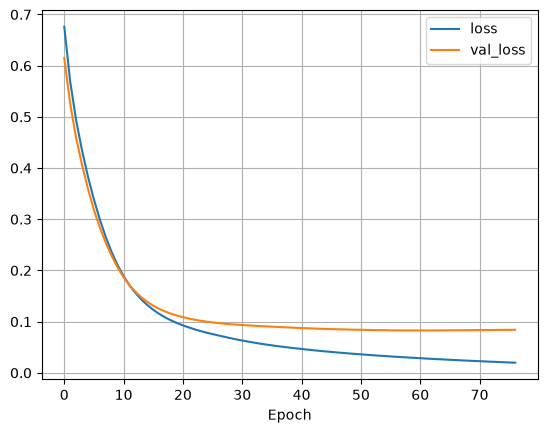

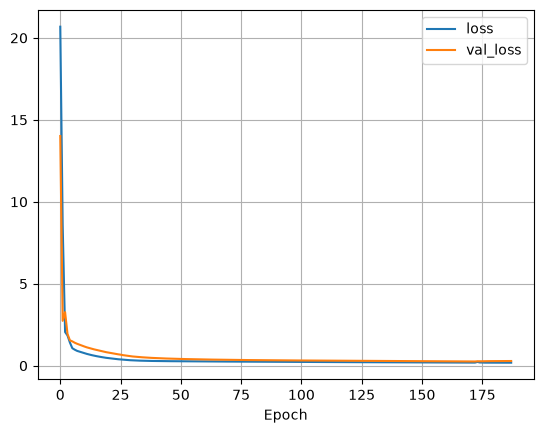

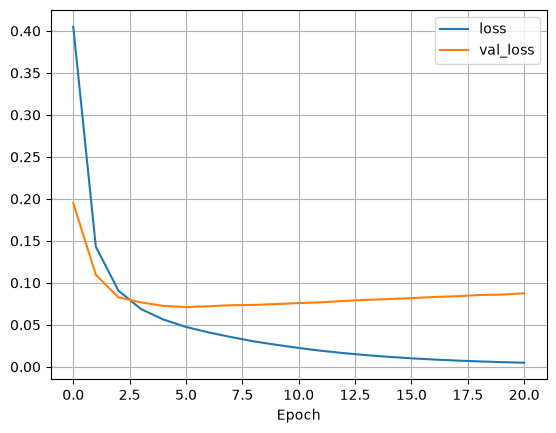

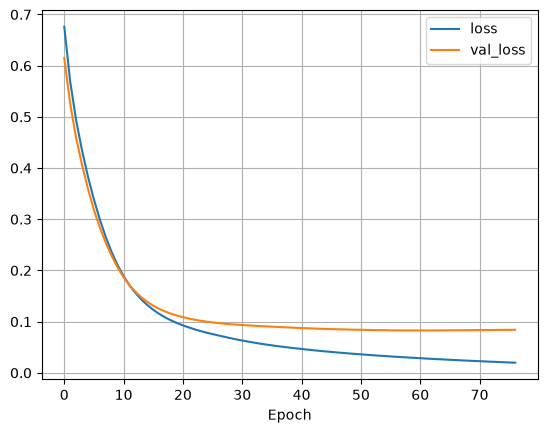

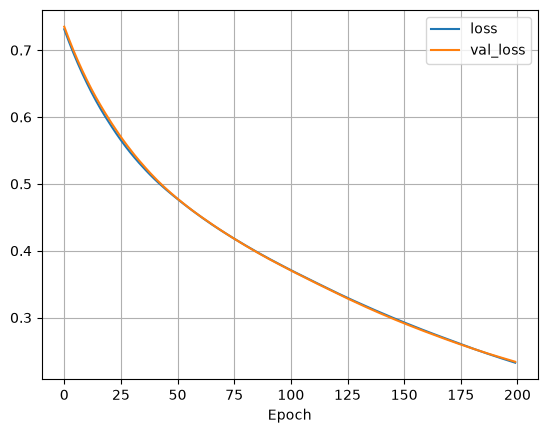

In [ ]:
results = [
    run_experiment(),
    run_experiment(scaled=False),
    run_experiment(hidden=(256,128)),
    run_experiment(dropout=0.3),
    run_experiment(optimizer='sgd')
]

results_df = pd.DataFrame(
    results,
    columns=['Test_accuracy', 'Recall']
)

In [ ]:
display(results_df)

The features not being scaled hurt the model the most. Loss and weights both are measured in raw numbers. If the features are not scaled, the features with the largest variances have the highest impact.

## P9: Trade-off. Move the decision threshold

The model outputs a **probability** of malignant. Using 0.5 as the cut-off is just a default.
**Lowering** the threshold flags more cases as malignant, which catches more cancers (higher recall) but raises more false alarms.

Using your baseline `bc_model` and `p_te` from P7, compute the number of **false negatives**, **false positives** and the **recall**
for thresholds 0.5, 0.3 and 0.1.

In [50]:
from sklearn.metrics import confusion_matrix, recall_score

for t in [0.5, 0.3, 0.1]:
    p_te = bc_model.predict(X_te_s, verbose=0).ravel()
    y_hat = [1 if x > t else 0 for x in p_te]

    tn, fp, fn, tp = confusion_matrix(y_test, y_hat).ravel()
    recall = recall_score(y_test, y_hat)

    print("Threshold: ", t, "   false negatives:", fn, "    false positives: ", fp, "   recall: ", recall)

Threshold:  0.5    false negatives: 2     false positives:  1    recall:  0.9523809523809523
Threshold:  0.3    false negatives: 1     false positives:  1    recall:  0.9761904761904762
Threshold:  0.1    false negatives: 1     false positives:  5    recall:  0.9761904761904762


✍️ Which threshold would you choose for a **screening** tool, and why? Who should make that decision: the data scientist alone, or with doctors?

The threshold of 0.3 should be used for the screening tool. It has the maximum recall without the false positives of an 0.5 threshold. This decision should be made with doctors both because they are the experts on the situation and because they need to know what the probability someone actually has when a positive is predicted.

## Reflection (submit with your notebook)

1. List the 8 steps of the recipe and, for each, one thing you did **differently** in Part 2 than in Part 1.
2. Why did we use `Dense(1, sigmoid)` + `binary_crossentropy` here but `Dense(10, softmax)` + `sparse_categorical_crossentropy` in Part 1?
3. What is data leakage, and where in Part 2 did we avoid it?
4. Your best model reaches, say, 97% accuracy. Would you deploy it in a hospital? What else would you want to know?

### 🚀 Stretch challenge

Try the same recipe on the **Wine Quality** dataset (UCI): https://archive.ics.uci.edu/ml/datasets/wine+quality
(direct download: https://archive.ics.uci.edu/static/public/186/wine+quality.zip, which contains `winequality-red.csv`; read it with `pd.read_csv(..., sep=";")`).
Predict a wine's quality score (0–10) as a **regression** task: last layer `Dense(1)`, loss `"mse"`, metric `"mae"`.
Then compare your mean absolute error with always predicting the mean quality.

1. The steps:
    1. Load the data. In part 2, the imports were in this step.
    2. Explore. In part 2, the targets were explored as values and not names.
    3. Split the data. In part 2, we also scaled the data in step 3.
    4. Build the model. We used the sigmoid activation instead of softmax.
    5. Compile. We used the adam optimizer instead of sgd.
    6. Train. We allowed for the model to run for up to 200 epochs instead of 30.
    7. Evaluate. These steps were almost identical. The one slight difference is in part two we map the output to binary instead of mapping the output to one of 10 options.
    8. Improve. In part two, we experimented with dropout and network size in addition to the experiments we conducted in part one.

2. In part two, we were mapping the out put to only one of two options, whereas in part one we had to map the output to which of the ten categories had the highest probability.
3. Data leakage is when data that is not supposed to be used for training influences the model weights. We avoided this in part 2 by splitting the data into a training set, validation set, and testing set, then only using the testing set once.
4. Whether or not I deploy it in a hospital primarily depends on the recall. The accuracy score is great, but we care more about catching cancer than avoiding false positives.